In [ ]:
#libraries and dependencies importation
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.datasets
from torch.utils.data import Subset
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

In [ ]:
# helper function of displaying multiple images
def show_images_withPred(images,label,pred,conf=None) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # Debug, plot figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.title("{} -> {}".format(label[i], pred[i]))
        #plt.title("Conf:{} \n {} -> {}".format(conf[i][pred[i]]*100,label[i], pred[i]))
        plt.axis('off')

    plt.show(block=True)


def show_images(images) -> None:
    n: int = images.size(0)
    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.axis('off')
    plt.show(block=True)

In [ ]:
# Hyperparameters and Data loaders
num_epochs = 10
num_classes = 10
batch_size = 256
learning_rate = 0.001

DATA_PATH = 'data/'
MODEL_STORE_PATH = 'models/'

# transforms to apply to the data
trans = transforms.Compose([transforms.ToTensor()])

# MNIST dataset
train_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=True, transform=trans, download=True)
test_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=False, transform=trans)

# Data loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=4, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=4, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 132MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 31.1MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 45.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.65MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [6]:
# neural network
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()

        # convolutional layers(3 layers)
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        # 1 fnn with dropout
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(3*3*128, 10)
        )

    def forward(self, x):
        out = self.features(x)
        out = self.classifier(out)

        return out

# Dynamically select GPU if available, otherwise fallback to CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = ConvNet()
model = model.to(device)
model.train()

ConvNet(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=1152, out_features=10, bias=True)
  )
)

In [7]:
# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [9]:
#model training
model.train()

for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    # Backprop and perform Adam optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track the accuracy
    if (i%150 == 0):
      _, predicted = torch.max(outputs.data, 1)
      correct = (predicted == labels).sum().item()
      print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%'
              .format(epoch + 1, num_epochs, i, len(train_loader), loss.item(),
                      (correct / labels.size(0)) * 100))

model.eval()
with torch.no_grad():
  correct = 0
  total = 0
  for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)
      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

      clean_acc = (correct / total) * 100

print('Accuracy of the ConvNet on test images: {} %'.format((correct / total) * 100))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1/10], Step [0/235], Loss: 2.3092, Accuracy: 8.59%
Epoch [1/10], Step [150/235], Loss: 0.2041, Accuracy: 92.97%
Epoch [2/10], Step [0/235], Loss: 0.0611, Accuracy: 98.05%
Epoch [2/10], Step [150/235], Loss: 0.0738, Accuracy: 97.66%
Epoch [3/10], Step [0/235], Loss: 0.0506, Accuracy: 98.44%
Epoch [3/10], Step [150/235], Loss: 0.0747, Accuracy: 97.27%
Epoch [4/10], Step [0/235], Loss: 0.0450, Accuracy: 99.22%
Epoch [4/10], Step [150/235], Loss: 0.0409, Accuracy: 99.22%
Epoch [5/10], Step [0/235], Loss: 0.0818, Accuracy: 96.09%
Epoch [5/10], Step [150/235], Loss: 0.0634, Accuracy: 98.05%
Epoch [6/10], Step [0/235], Loss: 0.0276, Accuracy: 98.83%
Epoch [6/10], Step [150/235], Loss: 0.0182, Accuracy: 99.22%
Epoch [7/10], Step [0/235], Loss: 0.0316, Accuracy: 98.83%
Epoch [7/10], Step [150/235], Loss: 0.0557, Accuracy: 98.44%
Epoch [8/10], Step [0/235], Loss: 0.0234, Accuracy: 99.61%
Epoch [8/10], Step [150/235], Loss: 0.0588, Accuracy: 98.83%
Epoch [9/10], Step [0/235], Loss: 0.0450,

FGSM Attack

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


FGSM (eps=0.08) accuracy on 10000 test images: 92.65 %


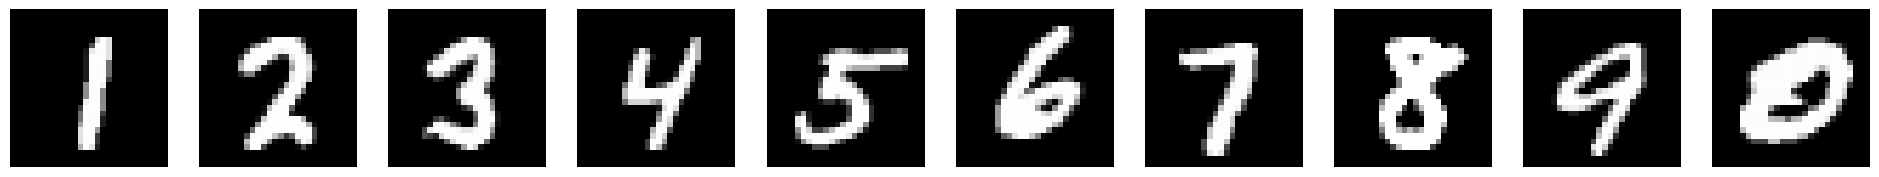

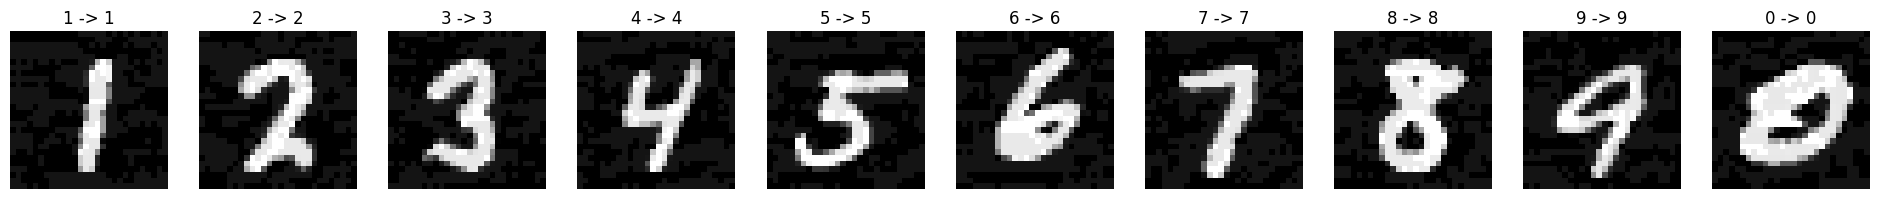

In [11]:
# FGSM method takes image + noise * sign wrt to grad of loss wrt to image
def fgsm_attack(model, criterion, images, labels, step_size):
  #variable that keeps gradients wrt to input image
  images.requires_grad = True
  outputs = model(images)
  model.zero_grad()
  loss = criterion(outputs, labels)
  loss.backward()

  #change direction of graph wrt to grad loss wrt to image
  if images.grad is not None:
    ae_images = images + step_size*images.grad.sign()
  else:
    ae_images = images

  # keep pixels in valid range
  ae_images = torch.clamp(ae_images, 0, 1)
  return ae_images.detach()

model.eval()

#variables for tracking correct predictions on adversarial examples.
correct = 0
total = 0

for images, labels in test_loader:

  #specifies runtime, dynamically choosing CPU or GPU
  images = images.to(device)
  labels = labels.to(device)

  #adverserial example generation using fgsm method
  ae_images = fgsm_attack(model, criterion, images, labels, step_size=0.08)

  #tests previously trained model on adversarial example images
  outputs = model(ae_images)

  #locates predicted class
  _, predicted = torch.max(outputs.data, 1)

  #keep track/count of images processed
  total += labels.size(0)
  correct += (predicted == labels).sum().item()

fgsm_acc_single = (correct / total) * 100
print('FGSM (eps=0.08) accuracy on 10000 test images: {} %'.format(fgsm_acc_single))

#display first 10 images with tensor removed from graph
show_images(images[:10].detach())                    # clean
show_images_withPred(ae_images[:10], labels[:10].tolist(), outputs[:10].argmax(dim=1).tolist())  # true -> predicted

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


eps: 0, Accuracy: 99.37 %
eps: 0.05, Accuracy: 96.88 %
eps: 0.1, Accuracy: 87.71 %
eps: 0.15, Accuracy: 64.30 %
eps: 0.2, Accuracy: 32.10 %
eps: 0.25, Accuracy: 15.82 %
eps: 0.3, Accuracy: 9.38 %


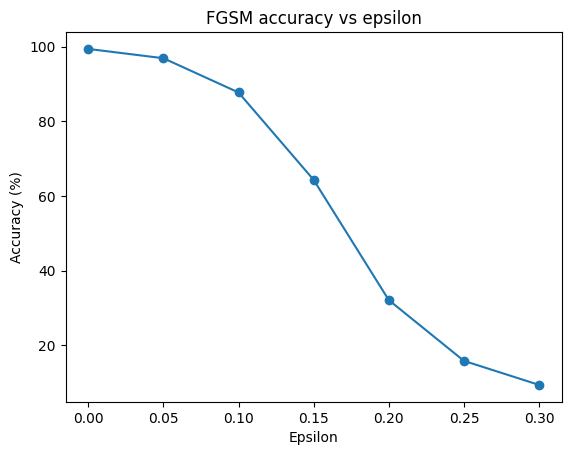

In [13]:
# Testing FGSM accuracy at varying perturbation size

#list of the varying pertubation within range [0,1] to be used for accuracy test
noise = [0, .05, .1, .15, .2, .25, .3]
#list to keep accuracy of fgsm attack wrt to noise
fgsm_acc = []
model.eval()

#iteratively the differing noise sizes
for eps in noise:
  correct = 0
  total = 0

  for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    #varying step size according to the noise
    ae_images = fgsm_attack(model, criterion, images, labels, step_size=eps)

    outputs = model(ae_images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  fgsm_acc.append((correct / total) * 100)
  print('eps: {}, Accuracy: {:.2f} %'.format(eps, fgsm_acc[-1]))

#display the accuracy of fgsm attack vs the varying pertubation sizes
# accuracy drop as eps grows
plt.plot(noise, fgsm_acc, marker='o')
plt.xlabel('Epsilon')
plt.ylabel('Accuracy (%)')
plt.title('FGSM accuracy vs epsilon')
plt.show()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


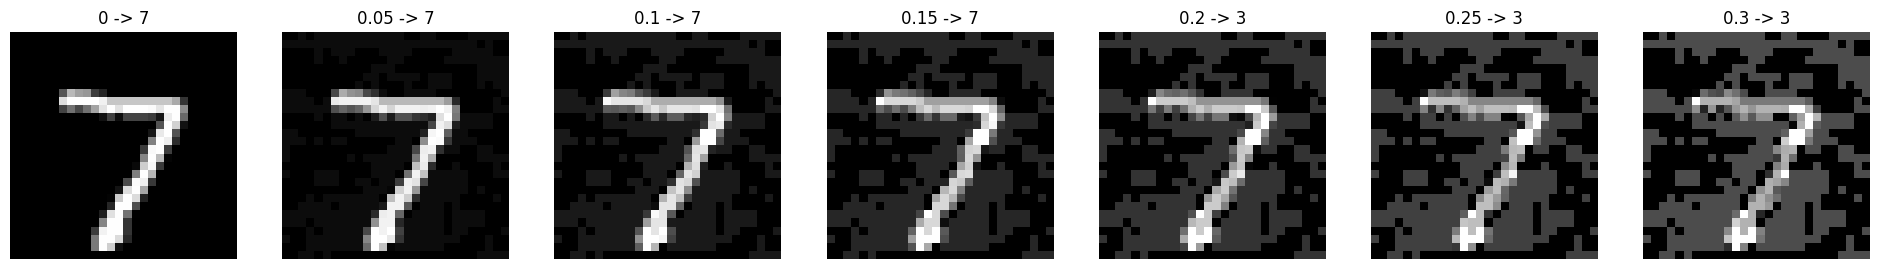

In [15]:
#test image at each epsilon, to judge how visible the perturbation is (to the human eye)
images, labels = next(iter(test_loader))
images, labels = images[:1].to(device), labels[:1].to(device)

eps_images = []
eps_preds = []

for eps in noise:

  # use .clone() so grads don't accumulate
  ae = fgsm_attack(model, criterion, images.clone(), labels, eps)

  eps_images.append(ae)
  eps_preds.append(model(ae).argmax(dim=1).item())

show_images_withPred(torch.cat(eps_images), noise, eps_preds)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


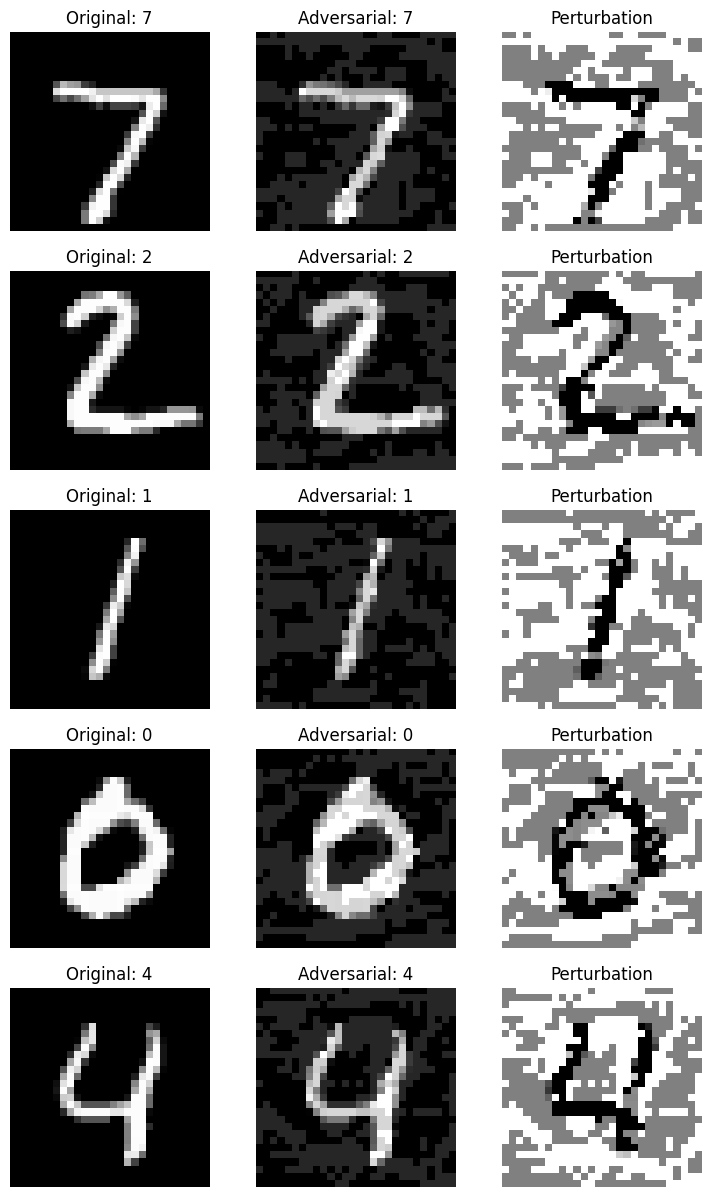

In [20]:
# comparision among original, adversarial and the added perturbation for 5 test images
images, labels = next(iter(test_loader))
images, labels = images[:5].to(device), labels[:5].to(device)

ae_images = fgsm_attack(model, criterion, images.clone(), labels, 0.15)

preds = model(ae_images).argmax(dim=1)

f = plt.figure(figsize=(9, 15))

for i in range(5):

  f.add_subplot(5, 3, 3*i+1)
  plt.imshow(images[i].cpu().squeeze(), cmap='gray')
  plt.title('Original: {}'.format(labels[i].item()))
  plt.axis('off')

  f.add_subplot(5, 3, 3*i+2)
  plt.imshow(ae_images[i].cpu().squeeze(), cmap='gray')
  plt.title('Adversarial: {}'.format(preds[i].item()))
  plt.axis('off')

  f.add_subplot(5, 3, 3*i+3)

  #displays perturbation only
  plt.imshow((ae_images[i] - images[i]).cpu().squeeze(), cmap='gray')
  plt.title('Perturbation')
  plt.axis('off')

plt.show()





PGD Attack

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


PGD (eps=0.08) accuracy on 10000 test images: 87.41 %


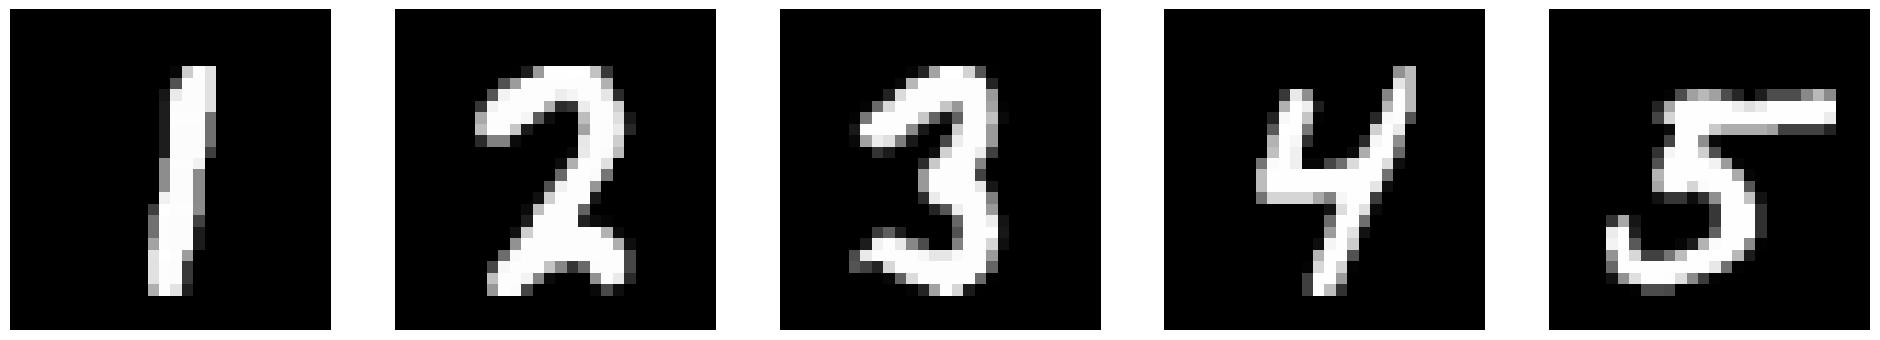

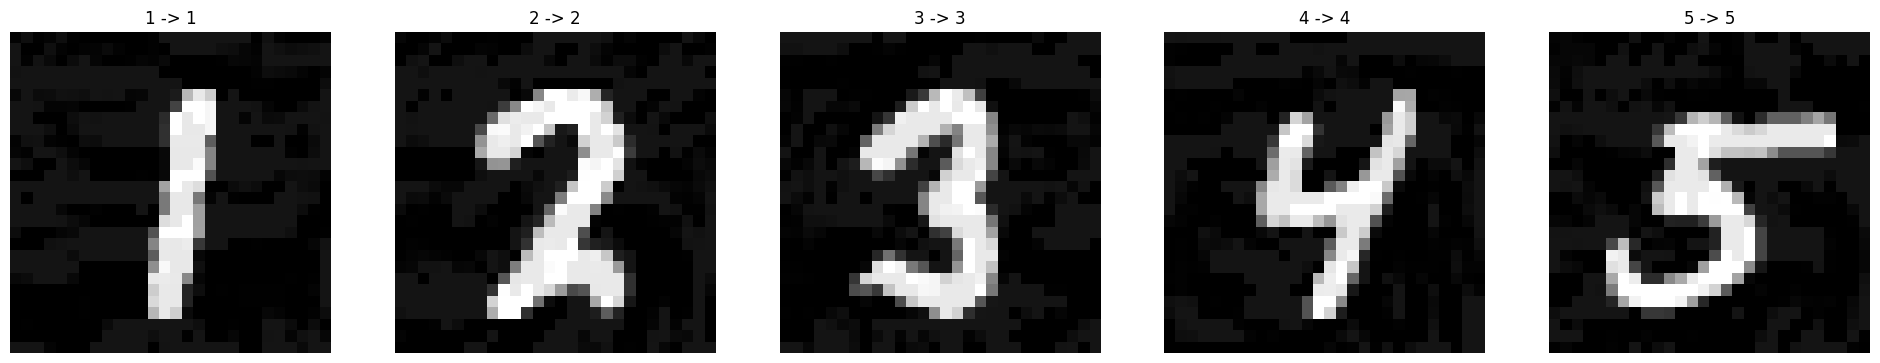

In [21]:
# PGD contains many small FGSM steps, each projected back into the eps-ball around the original
def pgd_attack(model, images, criterion, labels, eps=0.08, step_size=0.004, iters=40):
  images = images.to(device)
  labels = labels.to(device)

  #Keep the original images to ensure that the final adversarial image is within a defined distance from the original
  og_images = images.data

  #iteratively perform pgd process
  for i in range(iters):
    images.requires_grad = True
    outputs = model(images)
    model.zero_grad()
    cost = criterion(outputs, labels)
    cost.backward()

    #small FGSM step
    adv_images = images + step_size*images.grad.sign()
    eta = torch.clamp(adv_images - og_images, min=-eps, max=eps)
    images = torch.clamp(og_images + eta, min=0, max=1).detach_()

  return images

model.eval()

correct = 0
total = 0

# Iteratively go through each batch of images and labels in the test data loader
for images, labels in test_loader:
  images = images.to(device)
  labels = labels.to(device)

  #adverserial example generation using pgd method
  ae_images = pgd_attack(model, images, criterion, labels)

  outputs = model(ae_images)
  _, predicted = torch.max(outputs.data, 1)
  total += labels.size(0)
  correct += (predicted == labels).sum().item()

pgd_acc = (correct / total) * 100
print('PGD (eps=0.08) accuracy on 10000 test images: {} %'.format(pgd_acc))

show_images(images[:5].detach())
show_images_withPred(ae_images[:5], labels[:5].tolist(), outputs[:5].argmax(dim=1).tolist())

eps: 0, PGD Accuracy: 99.37 %
eps: 0.05, PGD Accuracy: 95.66 %
eps: 0.1, PGD Accuracy: 74.28 %
eps: 0.15, PGD Accuracy: 18.91 %
eps: 0.2, PGD Accuracy: 0.52 %
eps: 0.25, PGD Accuracy: 0.00 %
eps: 0.3, PGD Accuracy: 0.00 %


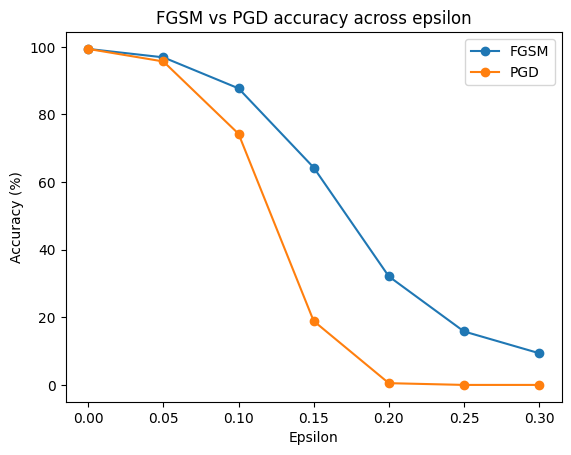

In [22]:
# PGD accuracy at each epsilon (same values used in the FGSM method implementation)
pgd_eps_acc = []
model.eval()

for eps in noise:
  correct = 0
  total = 0

  for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)

    #iteratively find pgd accuracy using varying pertubation from noise
    ae_images = pgd_attack(model, images, criterion, labels, eps=eps, step_size=eps/10)

    outputs = model(ae_images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  pgd_eps_acc.append((correct / total) * 100)
  print('eps: {}, PGD Accuracy: {:.2f} %'.format(eps, pgd_eps_acc[-1]))

# compare the accuracies of FGSM attack vs PGD attack on the same axes at the same (varied) pertubation
plt.plot(noise, fgsm_acc, marker='o', label='FGSM')
plt.plot(noise, pgd_eps_acc, marker='o', label='PGD')
plt.xlabel('Epsilon')
plt.ylabel('Accuracy (%)')
plt.title('FGSM vs PGD accuracy across epsilon')
plt.legend()
plt.show()

iters: 1, PGD Accuracy: 99.16 %
iters: 5, PGD Accuracy: 98.66 %
iters: 10, PGD Accuracy: 97.49 %
iters: 20, PGD Accuracy: 91.32 %
iters: 40, PGD Accuracy: 90.44 %


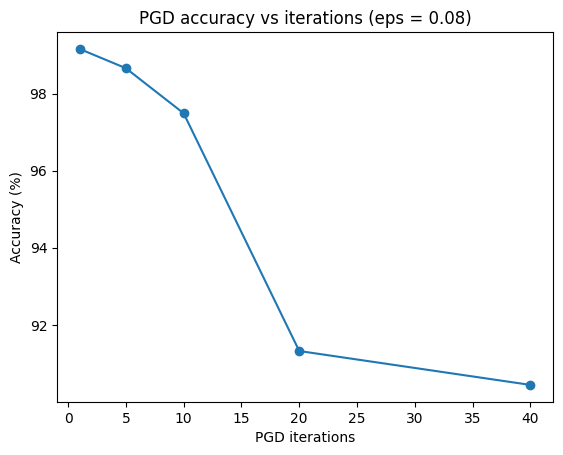

In [ ]:
# PGD accuracy vs number of iterations (eps = 0.08, step = 0.004)
iters_list = [1, 5, 10, 20, 40]
iter_acc = []
model.eval()

for n in iters_list:
  correct = 0
  total = 0

  for images, labels in test_loader:
    images = images.cuda()
    labels = labels.cuda()
    ae_images = pgd_attack(model, images, criterion, labels, eps=0.08, step_size=0.004, iters=n)

    outputs = model(ae_images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()
  iter_acc.append((correct / total) * 100)
  print('iters: {}, PGD Accuracy: {:.2f} %'.format(n, iter_acc[-1]))

plt.plot(iters_list, iter_acc, marker='o')
plt.xlabel('PGD iterations')
plt.ylabel('Accuracy (%)')
plt.title('PGD accuracy vs iterations (eps = 0.08)')
plt.show()

step: 0.001, PGD Accuracy: 97.45 %
step: 0.002, PGD Accuracy: 91.20 %
step: 0.004, PGD Accuracy: 90.44 %
step: 0.01, PGD Accuracy: 90.25 %
step: 0.02, PGD Accuracy: 90.46 %
step: 0.08, PGD Accuracy: 92.35 %


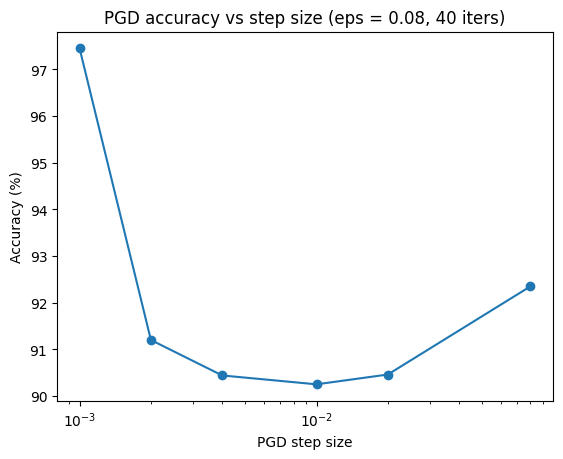

In [ ]:
# PGD accuracy vs step size (eps = 0.08, 40 iterations)
steps = [0.001, 0.002, 0.004, 0.01, 0.02, 0.08]
step_acc = []
model.eval()

for s in steps:
  correct = 0
  total = 0

  for images, labels in test_loader:
    images = images.cuda()
    labels = labels.cuda()
    ae_images = pgd_attack(model, images, criterion, labels, eps=0.08, step_size=s, iters=40)

    outputs = model(ae_images)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()
  step_acc.append((correct / total) * 100)
  print('step: {}, PGD Accuracy: {:.2f} %'.format(s, step_acc[-1]))

plt.plot(steps, step_acc, marker='o')
plt.xscale('log')                      # steps span almost two orders of magnitude
plt.xlabel('PGD step size')
plt.ylabel('Accuracy (%)')
plt.title('PGD accuracy vs step size (eps = 0.08, 40 iters)')
plt.show()

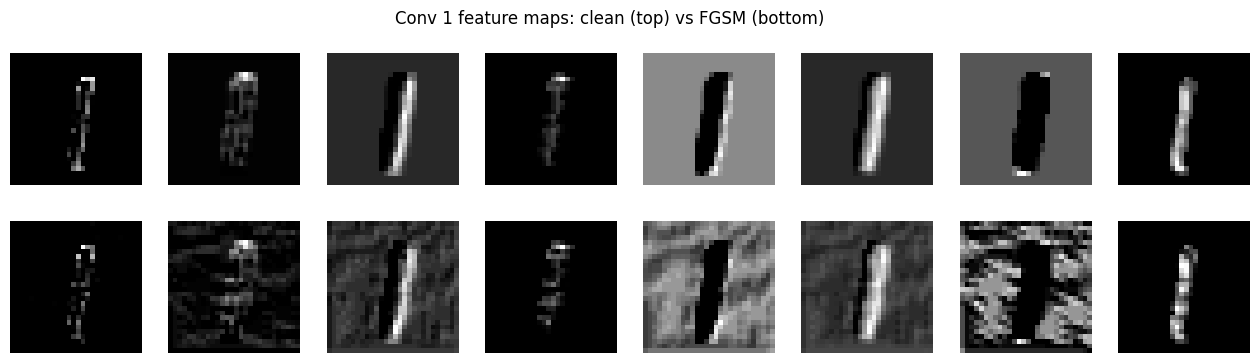

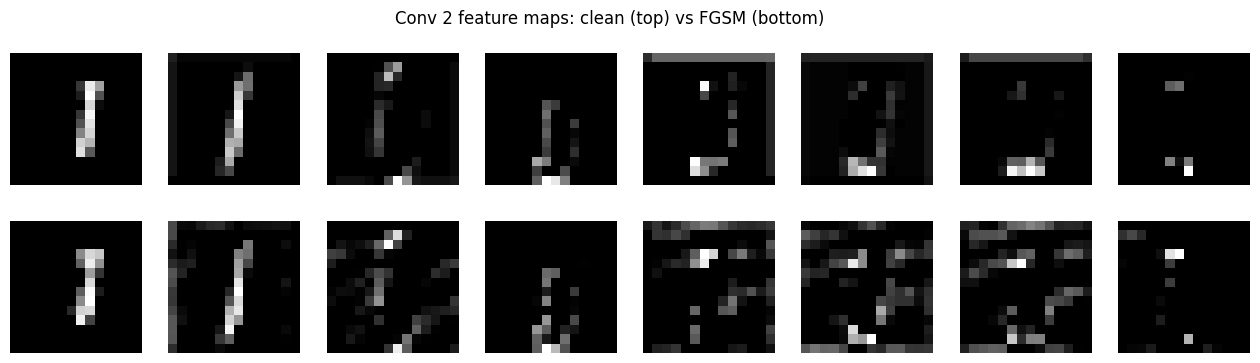

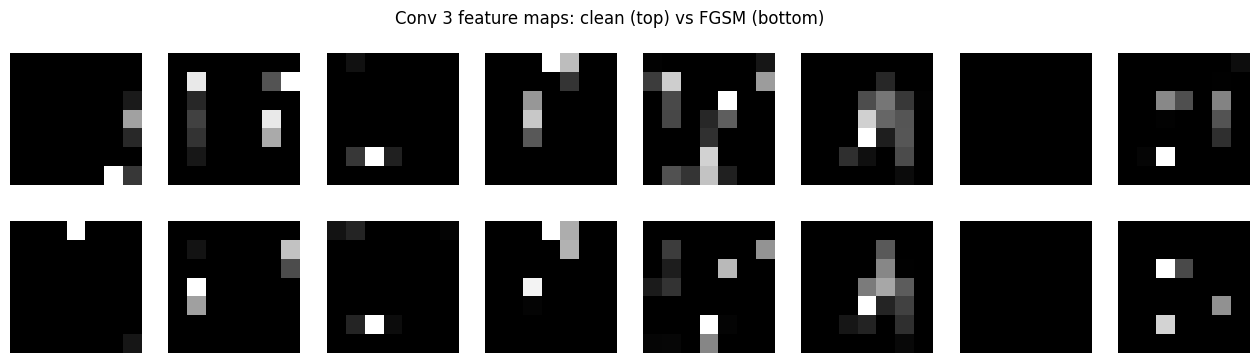

In [ ]:
#features/ feature map visualization
#test image and respective FGSM version
clean_img, label = images[:1].detach(), labels[:1]
adv_img = fgsm_attack(model, criterion, clean_img.clone(), label, 0.15)

with torch.no_grad():
  for layer_name, n_layer in [('Conv 1', 2), ('Conv 2', 5), ('Conv 3', 8)]:
    clean_maps = model.features[:n_layer](clean_img)[0]
    adv_maps = model.features[:n_layer](adv_img)[0]

    #sets the visual size
    f = plt.figure(figsize=(16, 4))

    #displays feature map for the first 8 features
    for i in range(8):
      f.add_subplot(2, 8, i+1)

      #displays top row with no pertubation
      plt.imshow(clean_maps[i].cpu(), cmap='gray')
      plt.axis('off')
      f.add_subplot(2, 8, i+9)
      #displays bottom row with adversarial examples
      plt.imshow(adv_maps[i].cpu(), cmap='gray')
      plt.axis('off')

    f.suptitle('{} feature maps: clean (top) vs FGSM (bottom)'.format(layer_name))
    plt.show()

Clean           99.37 %
FGSM (0.08)     93.54 %
PGD (0.08)      90.44 %


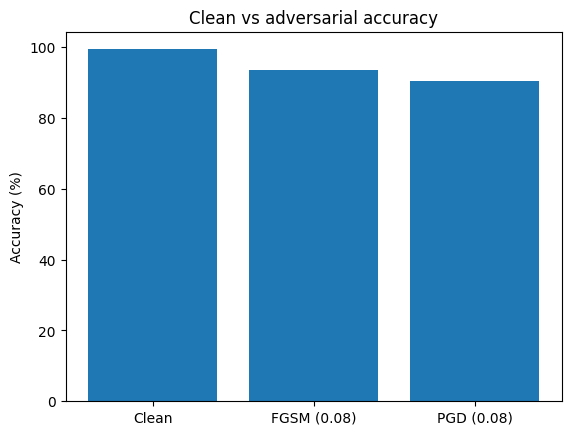

In [ ]:
# clean/ no pertubation vs adversarial accuracy at eps = 0.08
names = ['Clean', 'FGSM (0.08)', 'PGD (0.08)']
accs = [clean_acc,fgsm_acc_single, pgd_acc]

for n, a in zip(names, accs):
  print('{:<15} {:.2f} %'.format(n, a))

plt.bar(names, accs)
plt.ylabel('Accuracy (%)')
plt.title('Clean vs adversarial accuracy')
plt.show()